In [2]:
# Import the necessary libraries

import os
import json
import math
import torch
import sklearn
import numpy as np
import pandas as pd
from tqdm import tqdm
import seaborn as sns
from pathlib import Path
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from wordcloud import WordCloud

from sklearn.decomposition import PCA
import scipy.cluster.hierarchy as sch
from category_encoders import BinaryEncoder
from sklearn.metrics import pairwise_distances
from transformers import BertTokenizer, BertModel
from sklearn.metrics import silhouette_score, calinski_harabasz_score, silhouette_samples

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import SpectralClustering
from sklearn.cluster import AffinityPropagation

In [3]:
# A class to load the data from the json files

class DataLoader:
    def __init__(self, data_path):
        self.data_path = data_path

    def load_data(self):
        data_list = []

        for file in os.listdir(self.data_path):
            if file.endswith('.json'):
                data = self._extract_data(os.path.join(self.data_path, file))
                if all(value != '' for value in data.values()):
                    data_list.append(data)

        return pd.DataFrame(data_list)

    def _extract_data(self, file_path):
        with open(file_path, 'r', encoding='utf-8') as file:
            data = json.load(file)

        protocol = data.get('protocolSection', {})
        identification = protocol.get('identificationModule', {})
        description = protocol.get('descriptionModule', {})
        conditions = protocol.get('conditionsModule', {})
        design = protocol.get('designModule', {})
        eligibility = protocol.get('eligibilityModule', {})

        primary_purpose = design.get('designInfo', {}).get('primaryPurpose', '')


        extracted_data = {
            "NCT ID": self._try_except(identification, 'nctId'),
            "Study Type": self._try_except(design, 'studyType'),
            "Standard Ages": self._try_except(eligibility, 'stdAges', join=True),
            "Conditions": self._try_except(conditions, 'conditions', join=True),
            "Eligibility Criteria": self._try_except(eligibility, 'eligibilityCriteria'),
            "Sex": self._try_except(eligibility, 'sex')
        }

        return extracted_data

    def _try_except(self, data_dict, field_name, join=False):
        try:
            value = data_dict.get(field_name, '')
            if join and isinstance(value, list):
                return ", ".join(value)
            return value
        except Exception as e:
            print(f"Error extracting {field_name}: {str(e)}")
            return ''

In [4]:
def extract_raw_data(input_dir=None, output_file=None):
    '''
    Extracts raw data from the json files and saves it to a csv file.

    Parameters:
    - input_dir (str): The directory containing the input JSON files.
    - output_file (str): The name of the CSV file to save the raw data.

    Returns:
    None
    '''
    if input_dir is None or output_file is None:
        raise ValueError("Both 'input_dir' and 'output_file' must be specified.")

    # Assuming DataLoader is a class that loads data from JSON files
    dataloader = DataLoader(input_dir)
    raw_data = dataloader.load_data()

    # Save raw data to CSV
    raw_data.to_csv(output_file, index=False)

    print(f"Raw data extracted to {output_file}")

In [5]:
input_dir = Path(r'.\data\ctg-studies.json')
output_file = Path(r'.\data\ctg-studies.csv')

extract_raw_data(input_dir=input_dir, output_file=output_file)

Raw data extracted to data\ctg-studies.csv


In [6]:
raw_data = pd.read_csv(r'.\data\ctg-studies.csv')
raw_data.isna().sum()

NCT ID                  0
Study Type              0
Standard Ages           0
Conditions              0
Eligibility Criteria    0
Sex                     0
dtype: int64

In [7]:
raw_data.describe()

,NCT ID,Study Type,Standard Ages,Conditions,Eligibility Criteria,Sex
count,1266,1266,1266,1266,1266,1266
unique,1266,3,6,862,1254,3
top,NCT00019136,INTERVENTIONAL,"ADULT, OLDER_ADULT",Multiple Myeloma,"Inclusion Criteria:\n\n1. Age ≥18 years old, m...",ALL
freq,1,1198,836,78,3,1239


In [8]:
raw_data.head()

,NCT ID,Study Type,Standard Ages,Conditions,Eligibility Criteria,Sex
0,NCT00019136,INTERVENTIONAL,"ADULT, OLDER_ADULT",Ovarian Cancer,DISEASE CHARACTERISTICS:\n\n* Histologically p...,FEMALE
1,NCT00085930,INTERVENTIONAL,"CHILD, ADULT",Neuroblastoma,Inclusion Criteria:\n\nHigh risk neuroblastoma...,ALL
2,NCT00881920,INTERVENTIONAL,"ADULT, OLDER_ADULT","Lymphoma, Myeloma, Leukemia",INCLUSION CRITERIA:\n\nBLOOD PROCUREMENT:\n\n*...,ALL
3,NCT00902044,INTERVENTIONAL,"CHILD, ADULT, OLDER_ADULT",Sarcoma,INCLUSION CRITERIA:\n\nProcurement Eligibility...,ALL
4,NCT00924326,INTERVENTIONAL,"ADULT, OLDER_ADULT","Primary Mediastinal B-cell Lymphoma, Diffuse, ...",* INCLUSION CRITERIA:\n\n 1. Patient must hav...,ALL


In [9]:
raw_data['Study Type'].value_counts()

Study Type
INTERVENTIONAL     1198
OBSERVATIONAL        63
EXPANDED_ACCESS       5
Name: count, dtype: int64

In [10]:
raw_data['Standard Ages'].value_counts()

Standard Ages
ADULT, OLDER_ADULT           836
CHILD, ADULT, OLDER_ADULT    316
CHILD, ADULT                  97
ADULT                          9
CHILD                          7
OLDER_ADULT                    1
Name: count, dtype: int64

In [11]:
raw_data['Sex'].value_counts()

Sex
ALL       1239
FEMALE      15
MALE        12
Name: count, dtype: int64

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Bhanuteja\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Bhanuteja\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


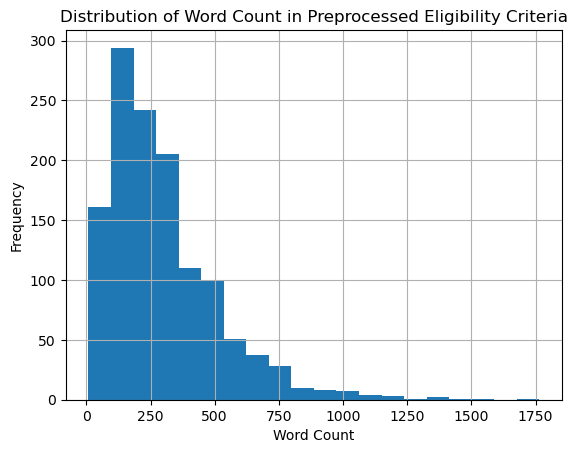

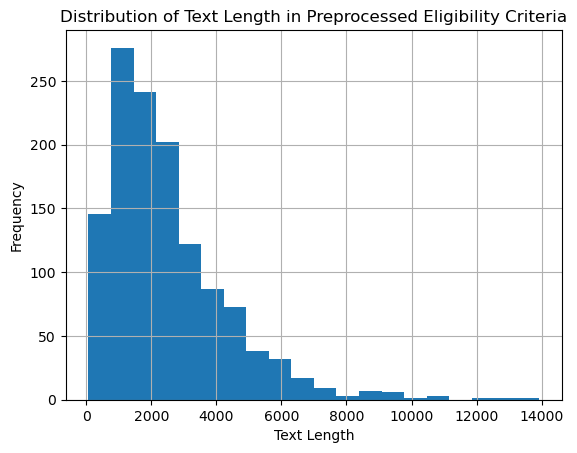

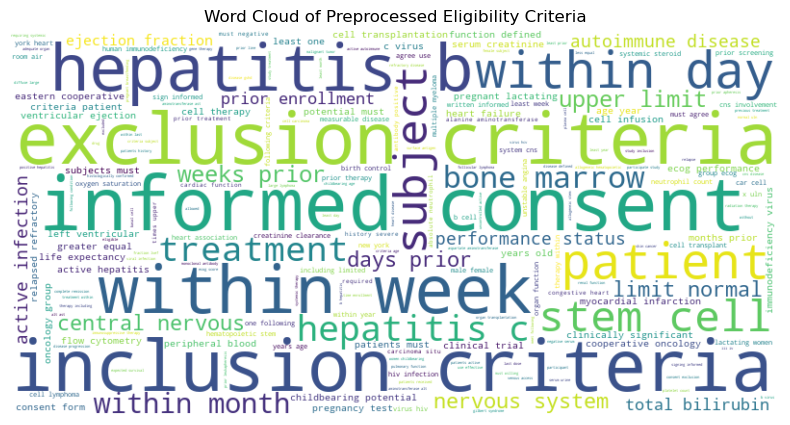

In [12]:
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import nltk
import string
nltk.download('punkt')
nltk.download('stopwords')

# Assuming 'raw_data' is your existing DataFrame with eligibility criteria text
# Make sure 'eligibility_criteria' is the column name containing the text

# Tokenization, lowercase, remove stopwords, and punctuations
stop_words = set(stopwords.words("english"))
punctuation = set(string.punctuation)

def preprocess_text(text):
    tokens = word_tokenize(text)
    tokens = [word.lower() for word in tokens if word.isalpha()]  # Remove non-alphabetic tokens
    tokens = [word for word in tokens if word not in stop_words]   # Remove stopwords
    tokens = [word for word in tokens if word not in punctuation]  # Remove punctuation
    return ' '.join(tokens)

# Preprocess eligibility criteria and add to DataFrame
raw_data['preprocessed_eligibility'] = raw_data['Eligibility Criteria'].apply(preprocess_text)

# Exploratory Data Analysis (EDA)
# You can perform various analyses depending on your goals. Here's a simple example:

# Word count distribution
raw_data['word_count'] = raw_data['preprocessed_eligibility'].apply(lambda x: len(x.split()))
raw_data['word_count'].hist(bins=20)
plt.title('Distribution of Word Count in Preprocessed Eligibility Criteria')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.savefig('./figures/word_count_distribution.png')
plt.show()

raw_data['text_length'] = raw_data['preprocessed_eligibility'].apply(len)
raw_data['text_length'].hist(bins=20)
plt.title('Distribution of Text Length in Preprocessed Eligibility Criteria')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.savefig('./figures/text_length_distribution.png')
plt.show()

# Top frequent words
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = ' '.join(raw_data['preprocessed_eligibility'])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Preprocessed Eligibility Criteria')
plt.savefig('./figures/word_cloud.png')
plt.show()


In [13]:
# Assuming 'raw_data' is your DataFrame with preprocessed eligibility criteria
count_long_texts = len(raw_data[raw_data['preprocessed_eligibility'].apply(len) > 5000])

print(f"Number of trials with preprocessed text length greater than 8000: {count_long_texts}")

Number of trials with preprocessed text length greater than 8000: 116


In [14]:
raw_data = raw_data[raw_data['preprocessed_eligibility'].apply(len) <= 5000]

In [22]:
bert_model = BertModel.from_pretrained("bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16")
tokenizer = BertTokenizer.from_pretrained("bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16")
hf_model = "bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16"
def calculate_optimal_chunk_size(max_token_limit, average_text_length, safety_margin=10):
    # Calculate an estimated chunk size with a safety margin
    optimal_chunk_size = (max_token_limit - safety_margin) // 2  # Assuming even distribution of tokens

    # Adjust the chunk size based on the average text length
    if optimal_chunk_size > average_text_length:
        optimal_chunk_size = min(optimal_chunk_size, average_text_length)

    return optimal_chunk_size

# Example usage
max_token_limit = 512  # Adjust based on your BERT model
average_text_length = math.ceil(raw_data['text_length'].mean()) # Calculate based on your preprocessed text

optimal_chunk_size = calculate_optimal_chunk_size(max_token_limit, average_text_length)
print(f"Optimal Chunk Size: {optimal_chunk_size}")

def chunk_text(text, chunk_size=256, overlap=64):
    tokens = tokenizer.encode_plus(text, add_special_tokens=True, return_tensors='pt')['input_ids'][0]
    chunks = [tokens[i:i+chunk_size] for i in range(0, len(tokens), chunk_size - overlap)]
    return chunks
def extract_features(text_chunks):
    chunk_embeddings = []
    for chunk in text_chunks:
        inputs = tokenizer(chunk, return_tensors="pt", padding=True, truncation=True, max_length=512)
        outputs = bert_model(**inputs)
        embeddings = outputs.last_hidden_state.mean(dim=1).squeeze().detach().numpy()
        chunk_embeddings.append(embeddings)
    
    # Concatenate all arrays in chunk_embeddings along the first axis
    concatenated_embeddings = np.concatenate(chunk_embeddings, axis=0)
    return concatenated_embeddings
def pad_and_concatenate_vectors(vectors):
    # Find the maximum length among the vectors
    max_length = max(len(vector) for vector in vectors)

    # Pad vectors to match the maximum length
    padded_vectors = [torch.cat([vector, torch.zeros(max_length - len(vector))]) for vector in vectors]

    # Concatenate padded vectors
    concatenated_vectors = torch.cat(padded_vectors)

    return concatenated_vectors

def extract_features(data=None, hf_model=None, col='NCT ID'):
    '''
    Extracts features from the eligibility criteria using the BERT model.

    Parameters:
    - data (pd.DataFrame): The data containing the eligibility criteria.
    - bert_model (str): The name of the BERT model to use.
    - tokenizer (str): The name of the tokenizer to use.

    Returns:
    pd.DataFrame: The data with the extracted features.
    '''
    if data is None or hf_model is None:
        raise ValueError("All parameters must be specified.")

    # Load the BERT model and tokenizer
    bert_model = BertModel.from_pretrained(hf_model)
    tokenizer = BertTokenizer.from_pretrained(hf_model)

    # Extract features from the eligibility criteria
    features = []
    for text in tqdm(data[col]):
        chunks = chunk_text(text)
        chunk_embeddings = extract_features(chunks, bert_model, tokenizer)
        features.append(chunk_embeddings)

    features = np.array(features)
    features = pad_and_concatenate_vectors(features)
    # Add the extracted features to the data
    features = pd.DataFrame(features)
    if col == 'NCT ID':
        features.columns = [f"feature_ec_{i}" for i in range(features.shape[1])]
    else:
        features.columns = [f"feature_cd_{i}" for i in range(features.shape[1])] 

    return features
# data = raw_data[['Study Type', 'Standard Ages', 'Sex', 'Conditions', 'preprocessed_eligibility']]
# encoder = BinaryEncoder()
# categorical_features = encoder.fit_transform(data[['Study Type', 'Sex', 'Standard Ages']])
# eligibility_features = extract_features(data.head(n=2), hf_model=hf_model, col='preprocessed_eligibility')

Optimal Chunk Size: 251


In [23]:
class BERTFeatureExtractor:
    def __init__(self, hf_model="bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16"):
        self.bert_model = BertModel.from_pretrained(hf_model)
        self.tokenizer = BertTokenizer.from_pretrained(hf_model)
        self.encoder = BinaryEncoder()

    def calculate_optimal_chunk_size(self, max_token_limit, average_text_length, safety_margin=10):
        optimal_chunk_size = (max_token_limit - safety_margin) // 2

        if optimal_chunk_size > average_text_length:
            optimal_chunk_size = min(optimal_chunk_size, average_text_length)

        return optimal_chunk_size

    def chunk_text(self, text, chunk_size=256, overlap=64):
        tokens = self.tokenizer.encode_plus(text, add_special_tokens=True, return_tensors='pt')['input_ids'][0]
        chunks = [tokens[i:i+chunk_size] for i in range(0, len(tokens), chunk_size - overlap)]
        return chunks

    def extract_features(self, text_chunks):
        chunk_embeddings = []
        for chunk in text_chunks:
            inputs = self.tokenizer(chunk, return_tensors="pt", padding=True, truncation=True, max_length=512)
            outputs = self.bert_model(**inputs)
            embeddings = outputs.last_hidden_state.mean(dim=1).squeeze().detach().numpy()
            chunk_embeddings.append(embeddings)

        concatenated_embeddings = np.concatenate(chunk_embeddings, axis=0)
        return concatenated_embeddings

    def pad_and_concatenate_vectors(self, vectors):
        max_length = max(len(vector) for vector in vectors)
        padded_vectors = [torch.cat([vector, torch.zeros(max_length - len(vector))]) for vector in vectors]
        concatenated_vectors = torch.cat(padded_vectors)
        return concatenated_vectors

    def extract_features_from_raw_data(self, raw_data):
        max_token_limit = 512  # Adjust based on your BERT model
        average_text_length = math.ceil(raw_data['text_length'].mean())  # Calculate based on your preprocessed text
        optimal_chunk_size = self.calculate_optimal_chunk_size(max_token_limit, average_text_length)

        categorical_features = self.encoder.fit_transform(raw_data[['Study Type', 'Sex', 'Standard Ages']])
        text_features = []

        for text in tqdm(raw_data['preprocessed_eligibility']):
            chunks = self.chunk_text(text, chunk_size=optimal_chunk_size)
            chunk_embeddings = self.extract_features(chunks)
            text_features.append(chunk_embeddings)

        text_features = np.array(text_features)
        text_features = self.pad_and_concatenate_vectors(text_features)

        features = np.concatenate([categorical_features.values, text_features.numpy()], axis=1)
        feature_columns = [f"feature_{i}" for i in range(features.shape[1])]
        features_df = pd.DataFrame(features, columns=feature_columns)

        return features_df

# Example usage
bert_feature_extractor = BERTFeatureExtractor()
features = bert_feature_extractor.extract_features_from_raw_data(raw_data.head(n=2))


In [24]:
def chunk_text(text, chunk_size=256, overlap=64):
    tokens = tokenizer.encode_plus(text, add_special_tokens=True, return_tensors='pt')['input_ids'][0]
    chunks = [tokenizer.decode(tokens[i:i + chunk_size]) for i in range(0, len(tokens))]
    return chunks

In [25]:
chunks = chunk_text(raw_data['preprocessed_eligibility'][0])

In [30]:
len(chunks[0].split())

172

In [41]:
tokenizer = BertTokenizer.from_pretrained(hf_model)
bert = BertModel.from_pretrained(hf_model)

In [58]:
text = """"
DISEASE CHARACTERISTICS:

* Histologically proven recurrent, resected recurrent, or residual ovarian epithelial cancer
* Failed prior standard effective therapy including cisplatin/carboplatin or paclitaxel
* Tumor positive for folate-binding protein by monoclonal antibody MOv18 binding
* Measurable disease by CT scan, MRI, ultrasound, or physical exam OR
* Minimal residual disease on laparotomy, laparoscopy, or peritoneal washings (i.e., disease not evaluable radiologically or on physical exam)

PATIENT CHARACTERISTICS:

Age:

* 18 and over

Performance status:

* ECOG 0 or 1

Hematopoietic:

* WBC greater than 3,000/mm\^3
* Platelet count greater than 100,000/mm\^3
* Hemoglobin greater than 9.0 g/dL
* No coagulation disorder

Hepatic:

* Bilirubin no greater than 2.0 mg/dL
* Other liver function tests less than 3 times upper limit of normal
* Hepatitis B antigen negative

Renal:

* Creatinine no greater than 2.0 mg/dL

Cardiovascular:

* No major cardiovascular illness
* If history of ischemic heart disease, congestive heart failure, or cardiac arrhythmias, not eligible to receive interleukin-2

Pulmonary:

* FEV_1 and DLCO greater than 70% predicted
* No major respiratory illness

Immunologic:

* Must have an intact immune system as evidenced by a positive reaction to Candida albicans, mumps, or tetanus toxoid skin tests on a standard anergy panel
* HIV negative
* No active systemic infection

Other:

* Not pregnant
* Negative pregnancy test
* Fertile patients must use effective contraception

PRIOR CONCURRENT THERAPY:

Biologic therapy:

* More than 2 weeks since prior biologic therapy

Chemotherapy:

* See Disease Characteristics
* More than 2 weeks since prior chemotherapy

Endocrine therapy:

* More than 2 weeks since prior endocrine therapy
* No concurrent steroids

Radiotherapy:

* More than 2 weeks since prior radiotherapy

Surgery:

* See Disease Characteristics
* Prior debulking allowed

Inclusion Criteria:

High risk neuroblastoma with a history of persistent or relapsed disease, or after initial therapy

Patients must have a life expectancy of at least 12 weeks

Patients must have recovered from the toxic effects of all prior chemotherapy before entering this study

Patients must not be currently receiving any investigational agents or have not received any tumor vaccines within the previous 6 weeks

Patients must have an ANC \> 500, platelet count \> 20,000

Patients who have received prior therapy with murine antibodies must have documentation of absence of human anti-mouse antibodies (HAMA) prior to enrollment on this study

Patients must have bilirubin less than 3 times the upper limit of normal

Patients must have AST less than 5 times the upper limit of normal

Patients must have serum creatinine less than 3 times upper limit of normal

Patient may not have cardiomegaly or bilateral pulmonary infiltrates on chest radiograph. Patients may have pulmonary metastatic lesions

Patient may not have an oxygen requirement as defined by pulse oximetry of \> 90% on room air

Patients must have Karnofsky score of \> 60% if \> 10 years old or Lansky performance score of greater than 60% if 10 years old or younger

Patients must have autologous transduced EBV-specific CTLs and transduced peripheral blood T-cells with 15% expression or greater of 14g2a.zeta determined by flow-cytometry

Sexually active patients must be willing to utilize one of the more effective birth control methods during the study and for 3 months after the study is concluded. The male partner should use a condom

Patients must not be pregnant or lactating

Patients must not have tumor in a location where enlargement could cause airway obstruction

Patients must not have a history of hypersensitivity to murine protein-containing products

Patients must not have a known sensitivity to rat monoclonal antibodies

Note: All labs must be collected within 10 days prior to initiation of study related treatment

Exclusion Criteria:

* Patients not meeting eligibility criteria
"""

tokenns = tokenizer.encode(tokenizer.tokenize(text))
tokenizer.convert_ids_to_tokens(tokenns)

['[CLS]',
 '"',
 'disease',
 'characteristics',
 ':',
 '*',
 'his',
 '##to',
 '##logical',
 '##ly',
 'proven',
 'rec',
 '##urrent',
 ',',
 'res',
 '##ect',
 '##ed',
 'rec',
 '##urrent',
 ',',
 'or',
 'residual',
 'o',
 '##var',
 '##ian',
 'ep',
 '##ith',
 '##elial',
 'cancer',
 '*',
 'failed',
 'prior',
 'standard',
 'effective',
 'therapy',
 'including',
 'cis',
 '##pl',
 '##atin',
 '/',
 'car',
 '##bo',
 '##pl',
 '##atin',
 'or',
 'pac',
 '##lita',
 '##x',
 '##el',
 '*',
 'tumor',
 'positive',
 'for',
 'f',
 '##olate',
 '-',
 'binding',
 'protein',
 'by',
 'mono',
 '##cl',
 '##onal',
 'antibody',
 'mo',
 '##v',
 '##18',
 'binding',
 '*',
 'me',
 '##asurable',
 'disease',
 'by',
 'ct',
 'scan',
 ',',
 'mri',
 ',',
 'ultrasound',
 ',',
 'or',
 'physical',
 'exam',
 'or',
 '*',
 'minimal',
 'residual',
 'disease',
 'on',
 'lap',
 '##aro',
 '##tom',
 '##y',
 ',',
 'lap',
 '##aro',
 '##sco',
 '##py',
 ',',
 'or',
 'per',
 '##ito',
 '##nea',
 '##l',
 'washing',
 '##s',
 '(',
 'i',
 '.',
 '

In [119]:
from transformers import BatchEncoding

def extract_features(text):
    inputs = tokenizer.encode_plus(text, return_tensors='pt')
    input_ids = inputs['input_ids']
    attention_masks = inputs['attention_mask']

    input_chunks = [
        {
            'input_ids': input_ids[:, i:i + 512].clone().detach(),
            'attention_mask': attention_masks[:, i:i + 512].clone().detach()
        } for i in range(0, input_ids.size(1), 500)
    ]

    input_chunks = [BatchEncoding(inp) for inp in input_chunks]


    outputs = []

    for inp in input_chunks:
        output = bert(**inp)  # Use **inp to pass dictionary as keyword arguments
        embeddings = output.last_hidden_state.mean(dim=1).squeeze().detach()
        outputs.append(embeddings)

    return torch.cat(outputs, dim=0)

def pad_and_concatenate_vectors(self, vectors):
        max_length = max(len(vector) for vector in vectors)
        padded_vectors = [torch.cat([vector, torch.zeros(max_length - len(vector))]) for vector in vectors]
        concatenated_vectors = torch.cat(padded_vectors)
        return concatenated_vectors

def pad(vectors):
     max_length = max(len(vector) for vector in vectors)
     padded_vectors = [torch.cat([vector, torch.zeros(max_length - len(vector))]).numpy() for vector in vectors]
     return padded_vectors
    

# Assuming 'text' is defined before calling the function
extracted_features = extract_features(text)


In [128]:
class BERTFeatureExtractor:
    def __init__(self, hf_model="bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16"):
        self.bert_model = BertModel.from_pretrained(hf_model)
        self.tokenizer = BertTokenizer.from_pretrained(hf_model)
        self.encoder = BinaryEncoder()


    def extract_features(self, text):
        inputs = self.tokenizer.encode_plus(text, return_tensors='pt')
        input_ids = inputs['input_ids']
        attention_masks = inputs['attention_mask']

        input_chunks = [
            {
                'input_ids': input_ids[:, i:i + 512].clone().detach(),
                'attention_mask': attention_masks[:, i:i + 512].clone().detach()
            } for i in range(0, input_ids.size(1), 500)
        ]

        input_chunks = [BatchEncoding(inp) for inp in input_chunks]

        outputs = []

        for inp in input_chunks:
            output = self.bert_model(**inp)  # Use **inp to pass dictionary as keyword arguments
            embeddings = output.last_hidden_state.mean(dim=1).squeeze().detach()
            outputs.append(embeddings)

        return torch.cat(outputs, dim=0).numpy()

    def pad(self, vectors):
        # max_length = max(len(vector) for vector in vectors)
        # padded_vectors = [np.concatenate(vector, np.zeros(max_length - len(vector))) for vector in vectors]
        # return padded_vectors
        print(type(vectors[0]))

    def extract_features_from_raw_data(self, raw_data):
       
        # categorical_features = self.encoder.fit_transform(raw_data[['Study Type', 'Sex', 'Standard Ages']])
        text_features = []

        for text in tqdm(raw_data['preprocessed_eligibility']):
            extracted_features = self.extract_features(text)
            text_features.append(extracted_features)
        
        text_features = self.pad(text_features)

        return text_features

# Example usage
bert_feature_extractor = BERTFeatureExtractor()
features = bert_feature_extractor.extract_features_from_raw_data(raw_data.head(n=1))


loading configuration file config.json from cache at C:\Users\Bhanuteja/.cache\huggingface\hub\models--bionlp--bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16\snapshots\e4a3d79282d3b1fc123b562de18b4c18b50a9176\config.json
Model config BertConfig {
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 1024,
  "initializer_range": 0.02,
  "intermediate_size": 4096,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 16,
  "num_hidden_layers": 24,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "transformers_version": "4.32.1",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 30522
}

loading weights file pytorch_model.bin from cache at C:\Users\Bhanuteja/.cache\huggingface\hub\models--bionlp--bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16\snapshots\e4a3d79282d3b1fc123b562de18b4c18b50a9176\pytorch_model.bin


: 